# 02 - Baseline models

Three classifiers on the cleaned Friday data (BENIGN / Bot / DDoS / PortScan):

| Model | Why |
|---|---|
| Logistic Regression | simple linear baseline: how hard is the problem? |
| Random Forest | strong, standard tree ensemble for flow features |
| XGBoost | gradient boosting, usually the strongest on tabular data |

No imbalance handling and no feature selection yet: this is the reference point
that notebook 03 tries to improve.

**Metrics.** Because Bot is well under 1% of flows, accuracy is misleading
(predicting "never Bot" still scores >99%). We report **macro-F1** (every class
counts equally) and **per-class recall**, especially for Bot.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)
from xgboost import XGBClassifier

sys.path.insert(0, str(Path.cwd().parent))
from src.data import feature_columns, LABEL_COL, PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

## 1. Load the cleaned data (saved by notebook 01)

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "friday_clean.parquet")
feats = feature_columns(df)
X = df[feats]
y_text = df[LABEL_COL]

encoder = LabelEncoder()
y = encoder.fit_transform(y_text)        # BENIGN, Bot, DDoS, PortScan -> 0, 1, 2, 3
classes = list(encoder.classes_)
print(X.shape, "features:", len(feats))
print(dict(zip(classes, np.bincount(y))))

(615433, 67) features: 67
{'BENIGN': np.int64(394777), 'Bot': np.int64(1948), 'DDoS': np.int64(128014), 'PortScan': np.int64(90694)}


## 2. Train / test split

80% train, 20% test, **stratified** so the rare Bot class appears in both parts in
the same proportion. The test set is never used for training or tuning.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("train:", X_train.shape, " test:", X_test.shape)
print("Bot flows in test set:", int((y_test == classes.index("Bot")).sum()))

train: (492346, 67)  test: (123087, 67)
Bot flows in test set: 389


## 3. Models

Logistic Regression needs scaled inputs. Flow features are extremely skewed
(durations from 0 to 10^8 microseconds), so we first apply a signed log,
`sign(x) * log(1 + |x|)`, then standardise. Tree models do not need either step.

In [4]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

models = {
    "Logistic Regression": make_pipeline(
        FunctionTransformer(signed_log),
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=8, learning_rate=0.1,
        tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE,
    ),
}

## 4. Train and evaluate

In [5]:
rows, predictions = [], {}
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    train_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    y_pred = model.predict(X_test)
    predict_s = time.perf_counter() - t0
    predictions[name] = y_pred

    _, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, labels=range(len(classes)),
                                                       zero_division=0)
    row = {
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro"),
        **{f"recall_{c}": r for c, r in zip(classes, recall)},
        **{f"f1_{c}": v for c, v in zip(classes, f1)},
        "train_s": train_s,
        "predict_s": predict_s,
    }
    rows.append(row)
    print(f"{name:20s} macro-F1={row['macro_f1']:.4f}  Bot recall={row['recall_Bot']:.4f}  ({train_s:.0f}s)")

results = pd.DataFrame(rows).set_index("model")

Logistic Regression  macro-F1=0.8839  Bot recall=0.3728  (5s)


Random Forest        macro-F1=0.9557  Bot recall=0.7763  (11s)


XGBoost              macro-F1=0.9558  Bot recall=0.7969  (26s)


In [6]:
summary_cols = ["accuracy", "macro_f1", "recall_Bot", "f1_Bot", "recall_DDoS",
                "recall_PortScan", "recall_BENIGN", "train_s"]
results[summary_cols].round(4)

,accuracy,macro_f1,recall_Bot,f1_Bot,recall_DDoS,recall_PortScan,recall_BENIGN,train_s
model,,,,,,,,
Logistic Regression,0.9975,0.8839,0.3728,0.5390,0.9997,0.9982,0.9997,5.3650
Random Forest,0.9989,0.9557,0.7763,0.8240,0.9998,0.9998,0.9995,11.3170
XGBoost,0.9989,0.9558,0.7969,0.8245,0.9998,0.9998,0.9993,26.3848


In [7]:
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
results.round(5).to_csv(REPORTS_DIR / "results_baseline.csv")

## 5. Per-class report for each model

In [8]:
for name, y_pred in predictions.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=classes, digits=4, zero_division=0))

===== Logistic Regression =====
              precision    recall  f1-score   support

      BENIGN     0.9964    0.9997    0.9980     78956
         Bot     0.9732    0.3728    0.5390       389
        DDoS     0.9995    0.9997    0.9996     25603
    PortScan     0.9994    0.9982    0.9988     18139

    accuracy                         0.9975    123087
   macro avg     0.9921    0.8426    0.8839    123087
weighted avg     0.9974    0.9975    0.9970    123087

===== Random Forest =====
              precision    recall  f1-score   support

      BENIGN     0.9988    0.9995    0.9991     78956
         Bot     0.8779    0.7763    0.8240       389
        DDoS     1.0000    0.9998    0.9999     25603
    PortScan     0.9999    0.9998    0.9999     18139

    accuracy                         0.9989    123087
   macro avg     0.9692    0.9438    0.9557    123087
weighted avg     0.9988    0.9989    0.9988    123087

===== XGBoost =====
              precision    recall  f1-score   suppor

## 6. Confusion matrices

Rows are the true class, columns the prediction, normalised per row, so the
diagonal is each class's recall. Look at the **Bot** row: which class are the
missed Bot flows confused with?

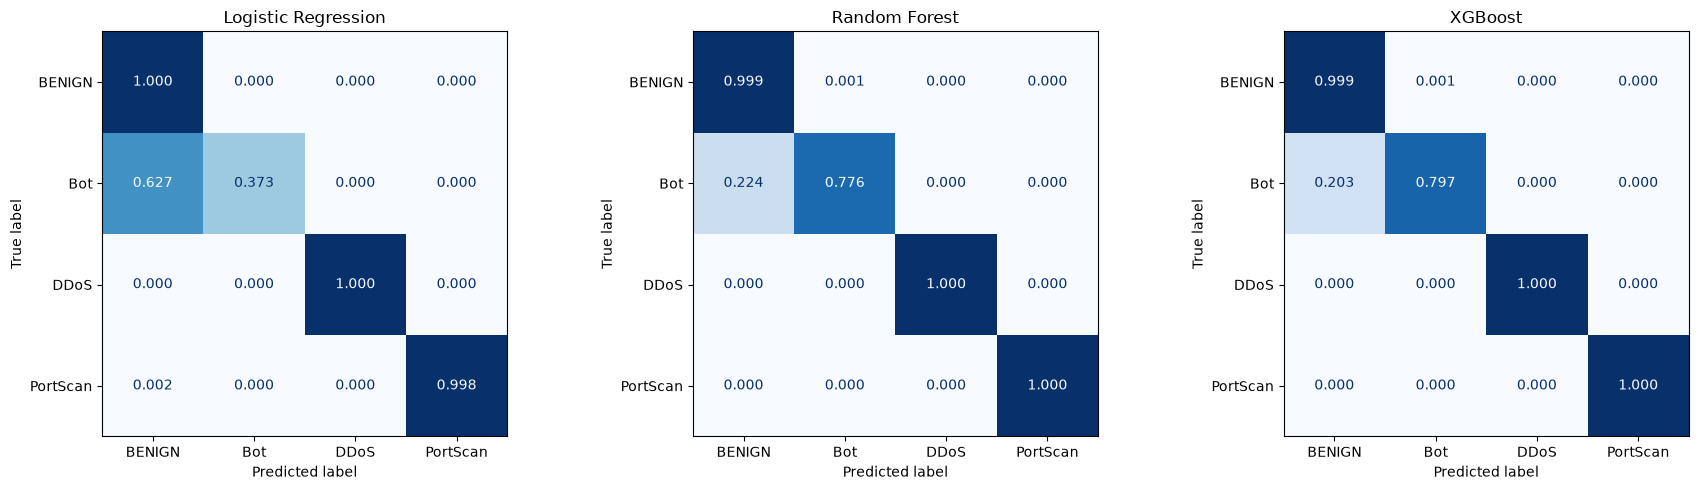

In [9]:
fig, axes = plt.subplots(1, len(predictions), figsize=(6 * len(predictions), 5))
for ax, (name, y_pred) in zip(np.atleast_1d(axes), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=classes, normalize="true",
        values_format=".3f", cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrices_baseline.png", dpi=150)
plt.show()

## 7. Which features do the tree models rely on?

A first look only; proper feature selection comes in notebook 03.

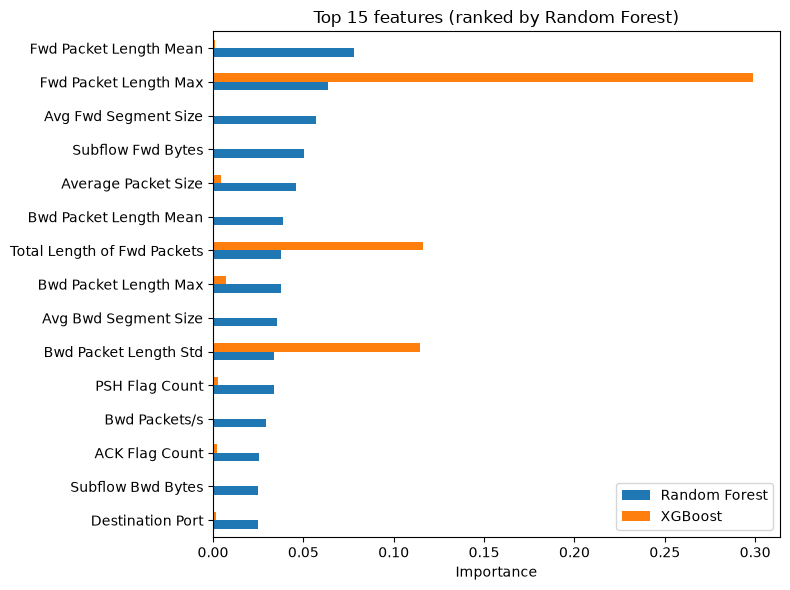

,Random Forest,XGBoost
Fwd Packet Length Mean,0.0780,0.0012
Fwd Packet Length Max,0.0637,0.2988
Avg Fwd Segment Size,0.0572,0.0000
Subflow Fwd Bytes,0.0506,0.0000
Average Packet Size,0.0458,0.0042
Bwd Packet Length Mean,0.0389,0.0004
Total Length of Fwd Packets,0.0376,0.1164
Bwd Packet Length Max,0.0374,0.0075
Avg Bwd Segment Size,0.0352,0.0000
Bwd Packet Length Std,0.0340,0.1144


In [10]:
importances = pd.DataFrame({
    "Random Forest": models["Random Forest"].feature_importances_,
    "XGBoost": models["XGBoost"].feature_importances_,
}, index=feats)
top = importances.sort_values("Random Forest", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
top[::-1].plot.barh(ax=ax)
ax.set_xlabel("Importance")
ax.set_title("Top 15 features (ranked by Random Forest)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_importance_baseline.png", dpi=150)
plt.show()
top.round(4)

## 8. Observations (fill in after running)

- Best model by macro-F1: ...
- Bot recall per model: ...
- Main confusion: ...
- Top features: ...